# 03 v2 - Live first-innings score prediction

**Why this notebook exists.** Notebook 02 predicted the first-innings total *before the match*
(venue, teams, toss, season). After ~100 steps the best model sat at MAE ~27 runs and R2 ~ 0 - that is the ceiling of
those inputs, not a bug. Notebook 03 (v1) changed the question: predict the final total **from the match state at the
end of each over**. v2 keeps that design and fixes the weak spots found in the v1 results.

## Where v1 ended (your real run)

| What | v1 result |
|------|-----------|
| Pre-match, `league_recent` only | MAE 26.0 (beat notebook 02's tuned RF at 27.0) |
| Pre-match, shrunk venue average | MAE 27.5 - **venue information added noise** |
| Mean MAE over overs 1-19 (validation 2021-24) | Ridge 16.72, Par table 17.51, Gradient boosting 17.95, naive 26.37 |
| Ridge late in the 2025-26 holdout (overs 17-19) | much worse than the Par table (e.g. 10.0 vs 6.6) |
| 80% range coverage | 73-74% early/mid (too narrow) |
| Fold-to-fold spread | ~5 runs at over 6, larger than most model differences |

## What v2 changes (each one is a hypothesis; the tables below say whether it worked)

| # | Change | Why | How it is judged |
|---|--------|-----|------------------|
| 1 | **Era-adjusted venue effect**: venue value = average of (score - league average *at that time*), shrunk | Old high-scoring seasons made raw venue averages wrong | Pre-match MAE vs v1 venue average, with CI |
| 2 | **Stage-wise model**: Ridge for overs 1-16, Par table for 17-19 | Ridge degrades in the death overs | Same-match comparison, with CI |
| 3 | **Match-level bootstrap CI** on every comparison | Folds are small and noisy | "noise" verdict when the CI includes 0 |
| 4 | **Phase features**: powerplay runs/wickets, last-3-overs rate, phase flag, wickets-in-hand x run-rate | Scoring behaviour differs by phase | Ridge (v2 features) vs Ridge (v1 features), with CI |
| 5 | **Interval fix**: calibrate on 2 seasons of out-of-sample errors | v1 coverage was 73-74% vs 80% target | Coverage table, 1 vs 2 calibration seasons |

## Experiment log (notebook 02, kept for reference)

| # | Technique | Result (MAE, runs) | Verdict |
|---|-----------|-------------------|---------|
| 1 | Fixed train-mean baseline (80/20 chrono split) | 37.1 | Weak: ignores scoring era |
| 2 | Rolling previous-3-seasons mean | 31.5 | Big jump, from *era* info only |
| 3 | Ridge (season, venue, city, teams, toss) | 31.7 | No gain over #2 |
| 4 | Random Forest, same features | 31.2 | Tiny gain |
| 5 | RF + team batting form | 32.7 | **Worse**: noise |
| 6 | Recency-weighted mean (decay 0.990-0.998) | 33.1-35.7 | Worse than rolling windows: too much old history |
| 7 | RF + league scoring trend | 32.3 | Worse |
| 8 | Season-only RF | 30.6 | Season alone beats full RF |
| 9 | Linear season trend | 32.4 | Cannot follow the 2023+ jump |
| 10 | Rolling last-30-match mean | 30.3 | Best simple model |
| 11 | Date-safe rolling baseline (same-day leak fix) | 30.3 | Correct fix, same score |
| 12 | RF + team/venue history | 32.0 | Worse |
| 13 | HistGradientBoosting | 30.6 | ~ baseline |
| 14 | Rolling-origin folds 2021-24 + 2025-26 holdout | - | **Right validation design** |
| 15 | Recent-30 vs 70/30 blend with previous seasons | 27.5 / 27.2 | Blend wins 1 of 4 seasons |
| 16 | Venue-name standardisation (60 -> 49 venues) | 27.3 -> 27.0 | Correct, small gain |
| 17 | Champion RF (standardised base) | 27.0 | Beats recent-30 (27.5) by 0.5 run |
| 18 | + team form / team history / bowling history / league environment | 27.5-29.3 | All worse than #17 |
| 19 | Gradient Boosting (huber) | 26.9 | Same as RF within noise |
| 20 | Error analysis | - | Predictions squeezed to 146-203 vs actual 68-287 |

> Rows 1-13 were scored on one 80/20 split (MAE ~30-37); rows 14+ use rolling folds validated on 2021-24 (MAE ~27).
> The drop is mostly an easier test set, not a better model. Compare numbers only inside the same block.

## Diagnosis (unchanged) - why pre-match predictions never "got right"
1. **Ceiling**: pre-match score std ~ 31-38, so MAE ~ 25-27 is what a good pre-match model looks like.
2. **Regression to the mean**: prediction std 2-11 vs actual 29-39.
3. **Regime shift**: ~160-172 (2017-22) -> 183 (2023) -> 190 (2024); trees on `season` cannot extrapolate.
4. **Tiny validation folds**: 60-74 matches, MAE standard error ~2-3 runs.
5. **Redundant / weak features**: `batting_team_won_toss` == `toss_decision == "bat"`; `city` duplicates `venue`; ~120 one-hot columns for ~1,000 rows.
6. **Unused ball-by-ball data.**

## Rules kept from v1
* One row per (match, end-of-over k), k = 1..19; target = **remaining runs**; prediction = runs so far + remaining.
* Pre-match context uses only matches with an earlier date.
* Season-based rolling-origin validation (2021-24); **2025-26 is evaluated once, at the end**.

In [1]:
import os, re, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import yaml
import matplotlib.pyplot as plt

from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.impute import SimpleImputer
from sklearn.linear_model import Ridge
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

warnings.filterwarnings("ignore", category=FutureWarning)

# Same convention as notebooks 01/02: notebook lives in /notebooks, data in /data/raw
PROJECT_ROOT = Path(os.environ.get("IPL_PROJECT_ROOT", Path.cwd().parent))
RAW_DATA_DIR = PROJECT_ROOT / "data" / "raw"
REPORTS_DIR = PROJECT_ROOT / "reports"
REPORTS_DIR.mkdir(parents=True, exist_ok=True)

print("Project root:", PROJECT_ROOT)
print("YAML files  :", len(list(RAW_DATA_DIR.glob("*.yaml"))))

Project root: c:\Users\amitb\Desktop\ME\Projects\Data_Analysis_Practice\cricket-analytics-lab
YAML files  : 1243


## 1. Parse first innings ball-by-ball

In [2]:
# 'retired hurt' is not a lost wicket (the batter may return), so it is not counted.
NOT_A_WICKET = {"retired hurt", "retired not out"}


def iter_raw_deliveries(innings_data):
    # Yield raw delivery dicts for both Cricsheet layouts.
    if "deliveries" in innings_data:                       # layout used by your files
        for entry in innings_data["deliveries"]:
            if isinstance(entry, dict) and entry:
                yield next(iter(entry.values()))
    elif "overs" in innings_data:                          # newer layout
        for over in innings_data["overs"]:
            for d in over.get("deliveries", []):
                yield d
    else:
        raise ValueError("Unknown innings layout: %s" % list(innings_data))


def parse_delivery(d):
    runs = d.get("runs") or {}
    extras = d.get("extras") or {}
    wk = d.get("wickets")
    if wk is None:
        w = d.get("wicket")
        wk = [w] if isinstance(w, dict) else []
    return {
        "total": runs.get("total", 0) or 0,
        "batter": runs.get("batter", runs.get("batsman", 0)) or 0,
        "wide": extras.get("wides", 0) or 0,
        "noball": extras.get("noballs", 0) or 0,
        "wickets": sum(1 for w in wk if w.get("kind") not in NOT_A_WICKET),
    }


def over_end_states(deliveries):
    # {k: (runs, wickets, boundaries)} measured when the 6th LEGAL ball of over k is bowled.
    # Wides and no-balls are not legal balls, so they never close an over.
    runs = wkts = bnd = legal = 0
    states = {}
    for d in deliveries:
        runs += d["total"]
        wkts += d["wickets"]
        if d["batter"] in (4, 6) and d["wide"] == 0:
            bnd += 1
        if d["wide"] == 0 and d["noball"] == 0:
            legal += 1
            if legal % 6 == 0:
                states[legal // 6] = (runs, wkts, bnd)
    return states, runs, wkts, legal


def load_first_innings(raw_dir):
    rows, states_by_match, errors = [], {}, []
    for path in sorted(raw_dir.glob("*.yaml")):
        try:
            with path.open("r", encoding="utf-8") as f:
                match = yaml.safe_load(f)
            info = match["info"]
            first = None
            for entry in match.get("innings", []):
                name, data = next(iter(entry.items()))
                if name == "1st innings":              # skips 2nd innings and Super Overs
                    first = data
                    break
            if first is None:
                continue
            deliveries = [parse_delivery(d) for d in iter_raw_deliveries(first)]
            states, final, wkts, legal = over_end_states(deliveries)
            rows.append({
                "match_id": path.stem,
                "date": pd.to_datetime(str(info["dates"][0])),
                "venue_raw": info.get("venue"),
                "batting_team": first.get("team"),
                "scheduled_overs": info.get("overs", 20),
                "final_score": final,
                "final_wickets": wkts,
                "legal_balls": legal,
            })
            states_by_match[path.stem] = states
        except Exception as exc:
            errors.append((path.name, repr(exc)))
    return pd.DataFrame(rows), states_by_match, errors


matches, states_by_match, load_errors = load_first_innings(RAW_DATA_DIR)
print("Matches parsed :", len(matches))
print("Load errors    :", len(load_errors), load_errors[:3])

Matches parsed : 1243
Load errors    : 0 []


In [3]:
# Keep only complete 20-over first innings (or all out). Rain-shortened innings have a different target.
matches["complete"] = (
    (matches["scheduled_overs"] == 20)
    & ((matches["legal_balls"] >= 120) | (matches["final_wickets"] >= 10))
)
print("Dropped (shortened / curtailed first innings):", int((~matches["complete"]).sum()))
matches = matches[matches["complete"]].drop(columns="complete").reset_index(drop=True)
matches["season"] = matches["date"].dt.year


# --- venue names: strip ', City' suffix + known renames (extend the alias dict if you spot more) ---
VENUE_ALIASES = {
    "feroz shah kotla": "Arun Jaitley Stadium",
    "sardar patel stadium": "Narendra Modi Stadium",
    "sheikh zayed stadium": "Zayed Cricket Stadium",
    "punjab cricket association stadium": "Punjab Cricket Association IS Bindra Stadium",
    "punjab cricket association is bindra stadium": "Punjab Cricket Association IS Bindra Stadium",
    "subrata roy sahara stadium": "Maharashtra Cricket Association Stadium",
}

def standardize_venue(v):
    if not isinstance(v, str):
        return "Unknown"
    key = re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip().lower()
    return VENUE_ALIASES.get(key, re.sub(r"\s+", " ", v.split(",")[0].replace(".", " ")).strip())

matches["venue"] = matches["venue_raw"].map(standardize_venue)
print("Venue labels: raw %d -> standardised %d" % (matches["venue_raw"].nunique(), matches["venue"].nunique()))
print(matches["venue"].value_counts().head(8).to_string())
print("\nVenues with < 5 matches (check these for missed aliases):")
print(matches["venue"].value_counts().loc[lambda s: s < 5].to_string())

Dropped (shortened / curtailed first innings): 28
Venue labels: raw 60 -> standardised 36
venue
Wankhede Stadium                                132
Eden Gardens                                    102
Arun Jaitley Stadium                            101
MA Chidambaram Stadium                           98
M Chinnaswamy Stadium                            97
Rajiv Gandhi International Stadium               89
Sawai Mansingh Stadium                           66
Punjab Cricket Association IS Bindra Stadium     60

Venues with < 5 matches (check these for missed aliases):
venue
Green Park                              4
Nehru Stadium                           4
Buffalo Park                            3
De Beers Diamond Oval                   3
Vidarbha Cricket Association Stadium    3
OUTsurance Oval                         2


## 2. Leak-safe pre-match context (v2: era-adjusted venue effect)
All values use only matches with `date <` the current match date (same-day matches never see each other).

* `league_recent` = mean of the last 60 earlier totals (the scoring era "right now").
* `excess` of a past match = its score minus the `league_recent` **that existed before that match**.
  A 170 in 2012 (league ~ 150) is +20; a 170 in 2024 (league ~ 190) is -20.
* `venue_effect` = sum of the venue's past `excess` / (matches there + 5). The "+5" shrinks small samples toward 0.
* `venue_prior` (v1 definition, raw venue totals shrunk to the league average) is kept so v1 and v2 can be compared.

In [4]:
def add_prior_context(df, league_window=60, venue_shrink=5.0, fallback=160.0):
    m = df.sort_values(["date", "match_id"]).reset_index(drop=True).copy()
    dates = m["date"].to_numpy()
    totals = m["final_score"].to_numpy(dtype=float)
    venues = m["venue"].to_numpy()
    n_all = len(m)

    # pass 1: scoring era at the time of every match (strictly earlier dates only)
    league = np.empty(n_all)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])
        recent = totals[prior][-league_window:]
        league[i] = recent.mean() if len(recent) >= 5 else fallback
    excess = totals - league            # how far this match was above the era average of ITS OWN time

    # pass 2: venue statistics from earlier matches
    venue_prior, venue_effect, venue_n = np.empty(n_all), np.empty(n_all), np.empty(n_all, dtype=int)
    for i in range(n_all):
        prior = np.flatnonzero(dates < dates[i])
        sv = prior[venues[prior] == venues[i]]
        n = len(sv)
        venue_n[i] = n
        venue_prior[i] = (totals[sv].sum() + venue_shrink * league[i]) / (n + venue_shrink)    # v1
        venue_effect[i] = excess[sv].sum() / (n + venue_shrink)                                # v2
    m["league_recent"], m["excess"] = league, excess
    m["venue_prior"], m["venue_effect"], m["venue_n"] = venue_prior, venue_effect, venue_n
    return m


matches = add_prior_context(matches)
print(matches[["venue", "final_score", "league_recent", "venue_prior", "venue_effect", "venue_n"]].tail(5).round(1).to_string())

# Sanity view: venues with a decent sample, using ALL matches (descriptive only, not used for training)
ve = (matches.groupby("venue").agg(n=("excess", "size"), raw_avg=("final_score", "mean"), era_adj_effect=("excess", "mean"))
      .query("n >= 15").sort_values("era_adj_effect"))
print("\nVenues with >= 15 matches: raw average vs era-adjusted effect (runs above the era average)")
ve.round(1)

                                                        venue  final_score  league_recent  venue_prior  venue_effect  venue_n
1210                                             Eden Gardens          203          196.2        172.7           2.5      101
1211             Himachal Pradesh Cricket Association Stadium          254          195.8        192.5          14.9       17
1212  Maharaja Yadavindra Singh International Cricket Stadium          243          197.3        185.1          -6.3       15
1213  Maharaja Yadavindra Singh International Cricket Stadium          214          197.9        188.0          -3.8       16
1214                                    Narendra Modi Stadium          155          198.8        182.7           3.2       52

Venues with >= 15 matches: raw average vs era-adjusted effect (runs above the era average)


,n,raw_avg,era_adj_effect
venue,,,
Bharat Ratna Shri Atal Bihari Vajpayee Ekana Cricket Stadium,27,175.4,-11.8
Zayed Cricket Stadium,37,158.9,-7.8
Kingsmead,15,152.0,-6.4
Sharjah Cricket Stadium,28,159.0,-5.9
MA Chidambaram Stadium,98,165.6,-4.7
Maharaja Yadavindra Singh International Cricket Stadium,17,186.6,-3.8
Dubai International Cricket Stadium,46,163.8,-2.7
Rajiv Gandhi International Stadium,89,168.7,-2.2
Dr DY Patil Sports Academy,36,161.0,-2.2


## 3. One row per (match, end of over k)
Features use only balls already bowled. Target = runs still to come.
v2 adds phase features: powerplay runs/wickets (overs 1-6, carried forward), last-3-overs run rate,
a phase flag (0 = overs 1-6, 1 = overs 7-15, 2 = overs 16+) and wickets-in-hand x run-rate.

In [5]:
TOTAL_OVERS = 20


def snapshot_features(states, k):
    # Features at the end of over k. Reads states[j] for j <= k ONLY (checked by the leak test below).
    def at(j):
        return states[j] if j >= 1 else (0, 0, 0)
    runs, wkts, bnd = states[k]
    r5, w5, _ = at(k - 5)
    r3, _, _ = at(k - 3)
    pp_runs, pp_wkts, _ = states[min(k, 6)]
    return {
        "over": k,
        "overs_left": TOTAL_OVERS - k,
        "runs": runs,
        "wickets": wkts,
        "wickets_in_hand": 10 - wkts,
        "run_rate": runs / k,
        "runs_last5": runs - r5,
        "wkts_last5": wkts - w5,
        "rr_last5": (runs - r5) / min(k, 5),
        "boundaries": bnd,
        # ---- v2 phase features ----
        "pp_runs": pp_runs,                          # powerplay total (partial while k < 6)
        "pp_wkts": pp_wkts,
        "rr_last3": (runs - r3) / min(k, 3),
        "phase": 0 if k <= 6 else (1 if k <= 15 else 2),
        "hand_x_rr": (10 - wkts) * runs / k,
    }


def add_linear_terms(df):
    # linear-friendly terms: Ridge cannot multiply features by itself
    df = df.copy()
    L = df["overs_left"]
    df["crr_remaining"] = df["run_rate"] * L
    df["form_remaining"] = df["rr_last5"] * L
    df["form3_remaining"] = df["rr_last3"] * L
    df["league_remaining"] = df["league_recent"] / TOTAL_OVERS * L
    df["venue_remaining"] = df["venue_effect"] / TOTAL_OVERS * L          # v2 (era-adjusted)
    df["venue_remaining_v1"] = df["venue_prior"] / TOTAL_OVERS * L        # v1 (raw shrunk average)
    df["hand_x_left"] = df["wickets_in_hand"] * L
    df["hand_x_crr_rem"] = df["wickets_in_hand"] * df["crr_remaining"] / 10
    df["phase_mid"] = (df["phase"] == 1).astype(int)
    df["phase_death"] = (df["phase"] == 2).astype(int)
    return df


def build_snapshots(matches, states_by_match, overs=range(1, TOTAL_OVERS)):
    rows = []
    for r in matches.itertuples():
        states = states_by_match[r.match_id]
        for k in overs:
            if k not in states:            # innings ended (all out) before this over
                continue
            f = snapshot_features(states, k)
            f.update(match_id=r.match_id, date=r.date, season=r.season,
                     venue_prior=r.venue_prior, venue_effect=r.venue_effect, venue_n=r.venue_n,
                     league_recent=r.league_recent, final_score=r.final_score)
            rows.append(f)
    snap = pd.DataFrame(rows)
    snap["remaining"] = snap["final_score"] - snap["runs"]
    return add_linear_terms(snap)


snap = build_snapshots(matches, states_by_match)
print("Snapshot rows:", len(snap), "| matches:", snap["match_id"].nunique())
snap.drop(columns=["date"]).head(3).round(2)

Snapshot rows: 23013 | matches: 1215


,over,overs_left,runs,wickets,wickets_in_hand,run_rate,runs_last5,wkts_last5,rr_last5,boundaries,...,crr_remaining,form_remaining,form3_remaining,league_remaining,venue_remaining,venue_remaining_v1,hand_x_left,hand_x_crr_rem,phase_mid,phase_death
0,1,19,3,0,10,3.0,3,0,3.0,0,...,57.0,57.0,57.0,152.0,0.0,152.0,190,57.0,0,0
1,2,18,21,0,10,10.5,21,0,10.5,4,...,189.0,189.0,189.0,144.0,0.0,144.0,180,189.0,0,0
2,3,17,27,0,10,9.0,27,0,9.0,5,...,153.0,153.0,153.0,136.0,0.0,136.0,170,153.0,0,0


## 4. Leak tests (these must pass before any model is trusted)

In [6]:
rng = np.random.default_rng(0)

# (a) snapshot features at over k must not change if every later over is deleted (includes the new phase features)
ids = rng.choice(matches["match_id"].to_numpy(), size=min(40, len(matches)), replace=False)
for mid in ids:
    states = states_by_match[mid]
    for k in [k for k in (3, 6, 10, 15, 19) if k in states]:
        full = snapshot_features(states, k)
        cut = snapshot_features({j: v for j, v in states.items() if j <= k}, k)
        assert full == cut, ("future information used", mid, k)
print("OK: over-k features (incl. phase features) use only balls up to over k")

# (b) pre-match context (league, venue_prior, era-adjusted venue_effect) must not change if the
#     current and all later matches are corrupted
probe = matches.sort_values("date").iloc[len(matches) // 2]
corrupt = matches.copy()
corrupt.loc[corrupt["date"] >= probe["date"], "final_score"] = 999
a = add_prior_context(matches).set_index("match_id").loc[probe["match_id"]]
b = add_prior_context(corrupt).set_index("match_id").loc[probe["match_id"]]
for col in ("league_recent", "venue_prior", "venue_effect"):
    assert np.isclose(a[col], b[col]), col
print("OK: league / venue / era-adjusted venue context uses only earlier dates")

# (b2) same-day matches must not see each other
day = matches.groupby("date").filter(lambda g: len(g) > 1)
if len(day):
    d0 = day["date"].iloc[0]
    same = add_prior_context(matches).query("date == @d0")
    assert same["league_recent"].nunique() == 1
    print("OK: matches on the same day share the same league_recent")

# (c) totals rebuilt from the over-by-over states are consistent with the final score
bad = [mid for mid in states_by_match if mid in set(matches["match_id"])
       and states_by_match[mid].get(19, (0,))[0] > matches.set_index("match_id").loc[mid, "final_score"]]
assert not bad, bad[:5]
print("OK: runs after over 19 never exceed the final score")

OK: over-k features (incl. phase features) use only balls up to over k
OK: league / venue / era-adjusted venue context uses only earlier dates
OK: matches on the same day share the same league_recent
OK: runs after over 19 never exceed the final score


## 5. Models and validation
Rolling-origin by season (validate 2021, 2022, 2023, 2024). 2025-26 stays untouched until section 8.

Models: naive run-rate x 20 | Par table | **Ridge** (v2 features) | **Ridge V1 features** (ablation: same Ridge, v1 feature set) |
Gradient boosting | **Stage-wise** (Ridge for overs 1-`STAGE_CUT`, Par table after).

In [7]:
RAW_FEATS_V1 = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "run_rate",
                "runs_last5", "wkts_last5", "rr_last5", "boundaries",
                "venue_prior", "venue_n", "league_recent"]
LIN_FEATS_V1 = RAW_FEATS_V1 + ["crr_remaining", "form_remaining", "league_remaining",
                               "venue_remaining_v1", "hand_x_left"]

RAW_FEATS = ["over", "overs_left", "runs", "wickets", "wickets_in_hand", "run_rate",
             "runs_last5", "wkts_last5", "rr_last5", "boundaries",
             "venue_effect", "venue_n", "league_recent",
             "pp_runs", "pp_wkts", "rr_last3", "phase", "hand_x_rr"]
LIN_FEATS = RAW_FEATS + ["crr_remaining", "form_remaining", "form3_remaining", "league_remaining",
                         "venue_remaining", "hand_x_left", "hand_x_crr_rem", "phase_mid", "phase_death"]
STAGE_CUT = 16          # Ridge for overs 1..16, Par table for 17..19 (verified on validation data in section 5b)


class CRRProjection:
    # Naive projection: current run rate x 20 overs.
    name = "Run-rate x 20 (naive)"
    def fit(self, tr): return self
    def predict_final(self, df): return df["run_rate"].to_numpy() * TOTAL_OVERS


class ParByOverWickets:
    # Average 'runs still to come' from training data, given (over, wickets lost).
    name = "Par table (over, wickets)"
    def fit(self, tr):
        t = tr.assign(w=tr["wickets"].clip(upper=6))
        self.tab = t.groupby(["over", "w"])["remaining"].mean()
        self.by_over = t.groupby("over")["remaining"].mean()
        return self
    def predict_final(self, df):
        w = df["wickets"].clip(upper=6)
        rem = [self.tab.get((o, ww), self.by_over.get(o, np.nan)) for o, ww in zip(df["over"], w)]
        return df["runs"].to_numpy() + np.array(rem)


class RidgeRemaining:
    name = "Ridge"
    feats = LIN_FEATS
    def fit(self, tr):
        self.m = make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10.0))
        self.m.fit(tr[self.feats], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[self.feats])


class RidgeV1Features(RidgeRemaining):
    name = "Ridge (v1 features)"
    feats = LIN_FEATS_V1


def make_hgb(**kw):
    return HistGradientBoostingRegressor(max_iter=300, learning_rate=0.05, max_leaf_nodes=15,
                                         min_samples_leaf=60, l2_regularization=1.0, random_state=0, **kw)

class HGBRemaining:
    name = "Gradient boosting"
    def fit(self, tr):
        self.m = make_hgb().fit(tr[RAW_FEATS], tr["remaining"])
        return self
    def predict_final(self, df): return df["runs"].to_numpy() + self.m.predict(df[RAW_FEATS])


class StageWise:
    name = "Stage-wise (Ridge + Par)"
    def fit(self, tr):
        self.early = RidgeRemaining().fit(tr)
        self.late = ParByOverWickets().fit(tr)
        return self
    def predict_final(self, df):
        is_late = (df["over"] > STAGE_CUT).to_numpy()
        return np.where(is_late, self.late.predict_final(df), self.early.predict_final(df))


MODELS = [CRRProjection, ParByOverWickets, RidgeRemaining, RidgeV1Features, HGBRemaining, StageWise]
NAIVE, PAR, RIDGE, RIDGE_V1, GB, STAGE = (M.name for M in MODELS)

FOLDS = [{"train_through": y - 1, "validate": y} for y in (2021, 2022, 2023, 2024)]
FOLDS = [f for f in FOLDS if (snap["season"] == f["validate"]).any()]   # skip folds with no data
HOLDOUT_START = 2025
dev = snap[snap["season"] < HOLDOUT_START]
holdout = snap[snap["season"] >= HOLDOUT_START]
print("Dev rows:", len(dev), "| holdout rows:", len(holdout), "| folds:", [f["validate"] for f in FOLDS])

Dev rows: 20313 | holdout rows: 2700 | folds: [2021, 2022, 2023, 2024]


In [8]:
def run_folds(folds, data):
    out = []
    for f in folds:
        tr = data[data["season"] <= f["train_through"]]
        va = data[data["season"] == f["validate"]]
        for M in MODELS:
            model = M().fit(tr)
            pred = model.predict_final(va)
            out.append(va[["match_id", "over", "final_score"]].assign(
                model=model.name, pred=pred, fold=f["validate"]))
    return pd.concat(out, ignore_index=True)


dev_preds = run_folds(FOLDS, dev)
dev_preds["abs_err"] = (dev_preds["pred"] - dev_preds["final_score"]).abs()

CHECKPOINTS = [1, 3, 6, 10, 15, 18]
by_over = dev_preds.pivot_table(index="over", columns="model", values="abs_err", aggfunc="mean")
print("Pooled validation MAE (runs) by over, folds 2021-2024")
by_over.loc[CHECKPOINTS].round(1)

Pooled validation MAE (runs) by over, folds 2021-2024


model,Gradient boosting,"Par table (over, wickets)",Ridge,Ridge (v1 features),Run-rate x 20 (naive),Stage-wise (Ridge + Par)
over,,,,,,
1,27.0,27.9,25.8,26.0,76.0,25.8
3,25.9,26.1,24.3,24.2,43.2,24.3
6,22.8,23.0,21.3,21.1,29.4,21.3
10,18.1,17.8,17.2,17.3,21.9,17.2
15,11.9,11.2,10.7,11.0,14.4,10.7
18,8.4,7.2,7.2,7.7,8.3,7.2


### 5a. Bootstrap tools (match-level)
Every comparison below is **paired by match**: for each match we take `error(reference) - error(challenger)`
(positive = challenger is better), then resample *matches* 2,000 times. Resampling matches (not rows) matters because
the 19 snapshots of one match are not independent. If the 95% interval includes 0 the verdict is **noise**.

In [9]:
PRE = "Pre-match (league avg)"


def per_match_table(preds, matches_df, over=None):
    # one row per match; columns = models (+ the pre-match baseline). over=None -> average over overs 1-19
    t = preds if over is None else preds[preds["over"] == over]
    t = t.pivot_table(index="match_id", columns="model", values="abs_err", aggfunc="mean")
    ref = matches_df.set_index("match_id")
    t[PRE] = (ref["final_score"] - ref["league_recent"]).abs().reindex(t.index)
    return t.dropna()


def boot_mean_ci(x, n_boot=2000, seed=0):
    x = np.asarray(x, dtype=float)
    rng = np.random.default_rng(seed)
    means = x[rng.integers(0, len(x), size=(n_boot, len(x)))].mean(axis=1)
    lo, hi = np.quantile(means, [0.025, 0.975])
    return x.mean(), lo, hi


PAIRS = [   # (challenger, reference)
    (RIDGE, RIDGE_V1),     # did the phase features + era-adjusted venue help?
    (STAGE, RIDGE),        # did the stage-wise switch help?
    (RIDGE, PAR),          # is Ridge better than a plain lookup table?
    (GB, RIDGE),           # is boosting better than Ridge?
    (RIDGE, PRE),          # how much does the live state add over the pre-match guess?
]


def compare(preds, matches_df, pairs=PAIRS, overs=CHECKPOINTS + ["ALL"]):
    rows = []
    for o in overs:
        t = per_match_table(preds, matches_df, None if o == "ALL" else o)
        for ch, ref in pairs:
            if ch not in t or ref not in t:
                continue
            gain, lo, hi = boot_mean_ci((t[ref] - t[ch]).to_numpy())
            verdict = "challenger better" if lo > 0 else ("reference better" if hi < 0 else "noise")
            rows.append(dict(over=o, challenger=ch, reference=ref, n_matches=len(t),
                             gain_runs=gain, ci_lo=lo, ci_hi=hi, verdict=verdict))
    return pd.DataFrame(rows)


def show_compare(df):
    for (ch, ref), g in df.groupby(["challenger", "reference"], sort=False):
        print("\n%s  vs  %s   (gain = reference error - challenger error, runs; 95%% match-bootstrap CI)" % (ch, ref))
        display(g.drop(columns=["challenger", "reference"]).set_index("over").round(2))

### 5b. Is the stage-wise cut justified by validation data alone?
Par table vs Ridge in the late overs, validation folds only.

In [10]:
cut_check = compare(dev_preds, matches, pairs=[(PAR, RIDGE)], overs=list(range(12, 20)))
print("Par table (challenger) vs Ridge (reference), validation folds 2021-24. Positive gain = Par is better.")
display(cut_check.drop(columns=["challenger", "reference"]).set_index("over").round(2))
print("Current STAGE_CUT =", STAGE_CUT, "-> Par table is used for overs", STAGE_CUT + 1, "-19.")
print("If the rows above do not show 'challenger better' (or at least a clearly positive gain) for those overs,\n"
      "the cut is not supported by validation data and should be moved. (Only the dev folds are used for this check.)")

Par table (challenger) vs Ridge (reference), validation folds 2021-24. Positive gain = Par is better.


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
12,277,0.01,-0.64,0.67,noise
13,277,-0.48,-1.03,0.09,noise
14,277,-0.66,-1.24,-0.06,reference better
15,277,-0.51,-1.08,0.05,noise
16,277,-0.19,-0.66,0.26,noise
17,275,-0.28,-0.76,0.21,noise
18,273,-0.07,-0.62,0.51,noise
19,270,2.20,1.60,2.80,challenger better


Current STAGE_CUT = 16 -> Par table is used for overs 17 -19.
If the rows above do not show 'challenger better' (or at least a clearly positive gain) for those overs,
the cut is not supported by validation data and should be moved. (Only the dev folds are used for this check.)


In [11]:
# ---- pre-match references on the validation seasons (what you can know before ball 1) ----
pre = matches[matches["season"].isin([f["validate"] for f in FOLDS])].copy()
fs, lg = pre["final_score"], pre["league_recent"]
pre_err = {
    "league_recent only": (fs - lg).abs(),
    "league + v1 venue_prior (raw shrunk avg)": (fs - pre["venue_prior"]).abs(),
    "league + v2 venue_effect (era-adjusted)": (fs - (lg + pre["venue_effect"])).abs(),
}
pre_mae = pre_err["league_recent only"].mean()
print("Pre-match MAE on validation seasons (n = %d matches):" % len(pre))
for k, v in pre_err.items():
    print("  %-42s %.2f" % (k, v.mean()))
print("  %-42s %.2f" % ("notebook 02 tuned RF (for reference)", 27.0))

for a, b in [("league + v2 venue_effect (era-adjusted)", "league + v1 venue_prior (raw shrunk avg)"),
             ("league + v2 venue_effect (era-adjusted)", "league_recent only")]:
    g, lo, hi = boot_mean_ci((pre_err[b] - pre_err[a]).to_numpy())
    print("\n  [%s]\n   vs [%s]\n   gain %.2f runs, 95%% CI [%.2f, %.2f] -> %s" %
          (a, b, g, lo, hi, "better" if lo > 0 else ("worse" if hi < 0 else "noise")))

Pre-match MAE on validation seasons (n = 277 matches):
  league_recent only                         26.01
  league + v1 venue_prior (raw shrunk avg)   27.51
  league + v2 venue_effect (era-adjusted)    25.59
  notebook 02 tuned RF (for reference)       27.00

  [league + v2 venue_effect (era-adjusted)]
   vs [league + v1 venue_prior (raw shrunk avg)]
   gain 1.92 runs, 95% CI [0.57, 3.30] -> better

  [league + v2 venue_effect (era-adjusted)]
   vs [league_recent only]
   gain 0.41 runs, 95% CI [-0.26, 1.10] -> noise


In [12]:
overall = dev_preds[dev_preds["model"] != NAIVE].groupby("model")["abs_err"].mean().sort_values()
print("Mean MAE over all overs (1-19), validation folds 2021-24 (naive excluded from the champion race):")
print(dev_preds.groupby("model")["abs_err"].mean().sort_values().round(2).to_string())

print("\nBootstrap comparisons on validation folds:")
dev_compare = compare(dev_preds, matches)
show_compare(dev_compare)

Mean MAE over all overs (1-19), validation folds 2021-24 (naive excluded from the champion race):
model
Stage-wise (Ridge + Par)     16.53
Ridge                        16.63
Ridge (v1 features)          16.72
Par table (over, wickets)    17.51
Gradient boosting            17.71
Run-rate x 20 (naive)        26.37

Bootstrap comparisons on validation folds:

Ridge  vs  Ridge (v1 features)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,277,0.21,0.01,0.40,challenger better
3,277,-0.05,-0.24,0.16,noise
6,277,-0.27,-0.61,0.10,noise
10,277,0.06,-0.14,0.27,noise
15,277,0.31,0.02,0.60,challenger better
18,273,0.51,0.24,0.79,challenger better
ALL,277,0.10,-0.02,0.22,noise



Stage-wise (Ridge + Par)  vs  Ridge   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,277,0.00,0.00,0.00,noise
3,277,0.00,0.00,0.00,noise
6,277,0.00,0.00,0.00,noise
10,277,0.00,0.00,0.00,noise
15,277,0.00,0.00,0.00,noise
18,273,-0.07,-0.62,0.51,noise
ALL,277,0.09,0.02,0.16,challenger better



Ridge  vs  Par table (over, wickets)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,277,2.13,1.22,3.07,challenger better
3,277,1.84,1.00,2.67,challenger better
6,277,1.71,0.88,2.52,challenger better
10,277,0.59,-0.13,1.29,noise
15,277,0.51,-0.05,1.08,noise
18,273,0.07,-0.51,0.62,noise
ALL,277,0.87,0.34,1.37,challenger better



Gradient boosting  vs  Ridge   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,277,-1.20,-2.34,-0.04,reference better
3,277,-1.68,-3.08,-0.32,reference better
6,277,-1.47,-2.65,-0.25,reference better
10,277,-0.86,-1.88,0.13,noise
15,277,-1.20,-1.92,-0.49,reference better
18,273,-1.24,-1.96,-0.53,reference better
ALL,277,-1.07,-1.83,-0.31,reference better



Ridge  vs  Pre-match (league avg)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,277,0.20,-0.86,1.26,noise
3,277,1.74,0.16,3.27,challenger better
6,277,4.68,2.53,6.65,challenger better
10,277,8.81,6.68,10.99,challenger better
15,277,15.35,12.94,17.80,challenger better
18,273,18.01,15.71,20.34,challenger better
ALL,277,9.33,7.46,11.17,challenger better


In [13]:
best_name = overall.index[0]
print("Per-fold MAE at over 6 / 10 / 15 for the best model (%s):" % best_name)
fold_view = (dev_preds[(dev_preds["model"] == best_name) & dev_preds["over"].isin([6, 10, 15])]
             .pivot_table(index="fold", columns="over", values="abs_err", aggfunc="mean").round(1))
display(fold_view)

# MAE with a 95% match-bootstrap interval for the champion and the pre-match reference
rows = []
for o in CHECKPOINTS:
    t = per_match_table(dev_preds, matches, o)
    for name in (best_name, PRE):
        m, lo, hi = boot_mean_ci(t[name].to_numpy())
        rows.append(dict(over=o, model=name, mae=m, ci_lo=lo, ci_hi=hi))
print("\nMAE with 95% CI:")
display(pd.DataFrame(rows).set_index(["over", "model"]).round(1))

Per-fold MAE at over 6 / 10 / 15 for the best model (Stage-wise (Ridge + Par)):


over,6,10,15
fold,,,
2021,22.5,17.6,11.3
2022,19.8,16.0,10.1
2023,19.0,17.3,10.5
2024,24.4,17.9,10.8



MAE with 95% CI:


mae  ci_lo  ci_hi
over model                                       
1    Stage-wise (Ridge + Par)  25.8   23.6   28.3
     Pre-match (league avg)    26.0   23.6   28.5
3    Stage-wise (Ridge + Par)  24.3   22.3   26.4
     Pre-match (league avg)    26.0   23.6   28.5
6    Stage-wise (Ridge + Par)  21.3   19.5   23.1
     Pre-match (league avg)    26.0   23.6   28.5
10   Stage-wise (Ridge + Par)  17.2   15.8   18.7
     Pre-match (league avg)    26.0   23.6   28.5
15   Stage-wise (Ridge + Par)  10.7    9.8   11.6
     Pre-match (league avg)    26.0   23.6   28.5
18   Stage-wise (Ridge + Par)   7.2    6.6    7.9
     Pre-match (league avg)    25.2   23.0   27.3

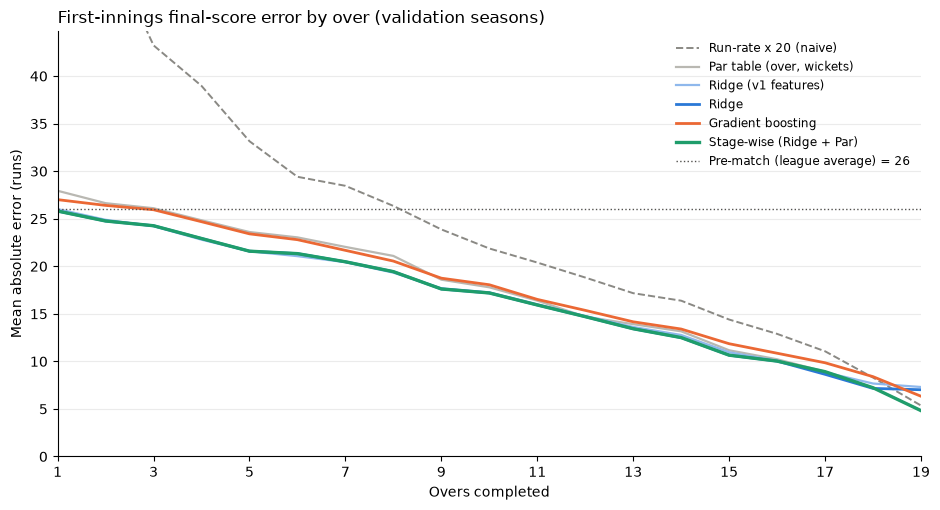

In [14]:
# ---- chart: MAE falls as the innings reveals itself ----
GRAY, GRAY2, BLUE, LBLUE, ORANGE, GREEN = "#8a8984", "#b9b8b2", "#2a78d6", "#8fb8ec", "#eb6834", "#1f9d6b"
style = {
    NAIVE:    dict(color=GRAY,   ls="--", lw=1.4),
    PAR:      dict(color=GRAY2,  ls="-",  lw=1.6),
    RIDGE_V1: dict(color=LBLUE,  ls="-",  lw=1.6),
    RIDGE:    dict(color=BLUE,   ls="-",  lw=2.0),
    GB:       dict(color=ORANGE, ls="-",  lw=2.0),
    STAGE:    dict(color=GREEN,  ls="-",  lw=2.4),
}
fig, ax = plt.subplots(figsize=(9.5, 5.2))
for name, st in style.items():
    if name in by_over:
        ax.plot(by_over.index, by_over[name], label=name, **st)
ax.axhline(pre_mae, color="#52514e", lw=1, ls=":", label="Pre-match (league average) = %.0f" % pre_mae)
model_cols = [c for c in by_over.columns if c != NAIVE]
ax.set_ylim(0, max(by_over[model_cols].max().max(), pre_mae) * 1.6)     # naive is huge early; clip so real models stay readable
ax.legend(frameon=False, loc="upper right", fontsize=8.5)
ax.set_xlabel("Overs completed")
ax.set_ylabel("Mean absolute error (runs)")
ax.set_title("First-innings final-score error by over (validation seasons)", loc="left")
ax.set_xlim(1, 19)
ax.set_xticks(range(1, 20, 2))
ax.grid(axis="y", alpha=0.25)
for s in ("top", "right"):
    ax.spines[s].set_visible(False)
plt.tight_layout()
plt.savefig(REPORTS_DIR / "live_first_innings_mae_by_over.png", dpi=150)
plt.show()

## 6. Honest ranges: 80% prediction interval (v2: 2 calibration seasons)
v1 coverage was 73-74% against an 80% target. v2 changes how the range is calibrated:

* For each of the **last N seasons before the target season**, fit the point model on everything *older than that season*
  and record its signed errors on that season (so the errors are genuinely out-of-sample).
* Per over (+-1 over smoothing) take the 10th/90th percentile of those errors and add them to the prediction.
* The point model used for the final prediction is trained on **all** seasons before the target season.

The calibration errors come from models trained on less data, so the range is slightly conservative - which is what
we want when v1 was too narrow. Compare N = 1 and N = 2 below.

In [15]:
CANDIDATES = [n for n in overall.index]          # champion among non-naive models
champion = overall.index[0]
POINT_MODEL = {M.name: M for M in MODELS}[champion]
print("Point model used for ranges:", POINT_MODEL.name)


class CalibratedRange:
    def __init__(self, point_cls, n_calib=2, lo_q=0.10, hi_q=0.90):
        self.point_cls, self.n_calib, self.lo_q, self.hi_q = point_cls, n_calib, lo_q, hi_q

    def fit(self, data):
        # data = every snapshot row available for training (seasons strictly before the target season)
        seasons = sorted(data["season"].unique())
        errs, overs = [], []
        for s in seasons[-self.n_calib:]:
            tr, va = data[data["season"] < s], data[data["season"] == s]
            if len(tr) == 0 or len(va) == 0:
                continue
            p = self.point_cls().fit(tr)
            errs.append((va["final_score"] - p.predict_final(va)).to_numpy())
            overs.append(va["over"].to_numpy())
        if not errs:
            raise ValueError("Not enough history to calibrate a range")
        err, ov = np.concatenate(errs), np.concatenate(overs)
        self.q = {}
        for k in range(1, TOTAL_OVERS):
            near = np.abs(ov - k) <= 1
            e = err[near] if near.sum() >= 30 else err
            self.q[k] = (np.quantile(e, self.lo_q), np.quantile(e, self.hi_q))
        self.pt = self.point_cls().fit(data)
        return self

    def predict(self, df):
        mid = self.pt.predict_final(df)
        lo = mid + np.array([self.q[k][0] for k in df["over"]])
        hi = mid + np.array([self.q[k][1] for k in df["over"]])
        return lo, mid, hi


def interval_eval(n_calib):
    rows = []
    for f in FOLDS:
        data = dev[dev["season"] <= f["train_through"]]
        va = dev[dev["season"] == f["validate"]]
        if len(data) == 0:
            continue
        lo, mid, hi = CalibratedRange(POINT_MODEL, n_calib).fit(data).predict(va)
        rows.append(va[["match_id", "over", "final_score"]].assign(lo=lo, mid=mid, hi=hi))
    iv = pd.concat(rows)
    iv["covered"] = (iv["final_score"] >= iv["lo"]) & (iv["final_score"] <= iv["hi"])
    iv["width"] = iv["hi"] - iv["lo"]
    return iv


def coverage_table(iv, overs=CHECKPOINTS):
    g = iv[iv["over"].isin(overs)].groupby("over")
    t = g.agg(coverage=("covered", "mean"), avg_range_width=("width", "mean"), n=("covered", "size"))
    t["+-95% (sampling)"] = 1.96 * np.sqrt(t["coverage"] * (1 - t["coverage"]) / t["n"])
    return t


iv_by_n = {n: interval_eval(n) for n in (1, 2)}
for n, iv in iv_by_n.items():
    print("\nCalibration seasons = %d | pooled coverage over all overs: %.3f | target 0.80" % (n, iv["covered"].mean()))
    display(coverage_table(iv).round(2))

Point model used for ranges: Stage-wise (Ridge + Par)

Calibration seasons = 1 | pooled coverage over all overs: 0.758 | target 0.80


,coverage,avg_range_width,n,+-95% (sampling)
over,,,,
1,0.72,69.87,277,0.05
3,0.74,67.97,277,0.05
6,0.74,62.80,277,0.05
10,0.73,48.22,277,0.05
15,0.78,34.86,277,0.05
18,0.79,21.34,273,0.05



Calibration seasons = 2 | pooled coverage over all overs: 0.778 | target 0.80


,coverage,avg_range_width,n,+-95% (sampling)
over,,,,
1,0.77,74.62,277,0.05
3,0.75,70.10,277,0.05
6,0.74,63.11,277,0.05
10,0.75,50.15,277,0.05
15,0.81,35.45,277,0.05
18,0.81,22.22,273,0.05


## 7. Final holdout (2025-26) - evaluated once
Everything below is computed a single time. Do not re-run it with changed settings to chase a better number -
that turns the holdout into another validation set.

*Note:* the idea of a stage-wise switch near over 16-17 came from looking at the v1 holdout, so for that one decision
the 2025-26 data is not completely fresh. Section 5b is the validation-only evidence for it.

In [16]:
print("Champion chosen on validation folds only:", champion)

if len(holdout):
    final_models = [M().fit(dev) for M in MODELS]
    hp = pd.concat([
        holdout[["match_id", "over", "final_score"]].assign(
            model=m.name, pred=m.predict_final(holdout)) for m in final_models], ignore_index=True)
    hp["abs_err"] = (hp["pred"] - hp["final_score"]).abs()
    holdout_tbl = hp.pivot_table(index="over", columns="model", values="abs_err", aggfunc="mean")
    print("\nHoldout MAE by over (2025-26):")
    display(holdout_tbl.loc[[o for o in CHECKPOINTS if o in holdout_tbl.index]].round(1))
    holdout_tbl.to_csv(REPORTS_DIR / "live_first_innings_holdout_mae.csv")

    print("Mean MAE over overs 1-19:")
    print(hp.groupby("model")["abs_err"].mean().sort_values().round(2).to_string())

    print("\nBootstrap comparisons on the holdout:")
    holdout_compare = compare(hp, matches[matches["season"] >= HOLDOUT_START])
    show_compare(holdout_compare)
    holdout_compare.to_csv(REPORTS_DIR / "live_first_innings_holdout_bootstrap.csv", index=False)

    # interval coverage on the holdout: calibrate on the last 2 dev seasons, predict 2025-26
    lo, mid, hi = CalibratedRange(POINT_MODEL, 2).fit(dev).predict(holdout)
    hv = holdout[["over", "final_score"]].assign(lo=lo, mid=mid, hi=hi)
    hv["covered"] = (hv["final_score"] >= hv["lo"]) & (hv["final_score"] <= hv["hi"])
    hv["width"] = hv["hi"] - hv["lo"]
    print("\nHoldout 80%% range coverage: pooled %.3f" % hv["covered"].mean())
    display(coverage_table(hv).round(2))
else:
    print("No 2025+ matches in the data - holdout skipped.")

by_over.round(3).to_csv(REPORTS_DIR / "live_first_innings_validation_mae_by_over.csv")
dev_compare.to_csv(REPORTS_DIR / "live_first_innings_validation_bootstrap.csv", index=False)

Champion chosen on validation folds only: Stage-wise (Ridge + Par)

Holdout MAE by over (2025-26):


model,Gradient boosting,"Par table (over, wickets)",Ridge,Ridge (v1 features),Run-rate x 20 (naive),Stage-wise (Ridge + Par)
over,,,,,,
1,27.8,34.7,28.0,28.2,71.7,28.0
3,24.6,32.1,25.2,25.1,44.9,25.2
6,20.3,24.6,20.4,20.4,31.0,20.4
10,17.1,18.9,16.8,16.6,22.4,16.8
15,11.1,11.7,11.2,10.8,13.9,11.2
18,7.5,6.6,8.9,10.0,7.9,6.6


Mean MAE over overs 1-19:
model
Stage-wise (Ridge + Par)     16.72
Gradient boosting            16.90
Ridge                        17.05
Ridge (v1 features)          17.13
Par table (over, wickets)    19.33
Run-rate x 20 (naive)        25.97

Bootstrap comparisons on the holdout:

Ridge  vs  Ridge (v1 features)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,143,0.19,-0.12,0.48,noise
3,143,-0.04,-0.38,0.29,noise
6,143,0.07,-0.58,0.73,noise
10,143,-0.17,-0.45,0.11,noise
15,142,-0.36,-0.79,0.08,noise
18,139,1.13,0.61,1.62,challenger better
ALL,143,0.08,-0.11,0.28,noise



Stage-wise (Ridge + Par)  vs  Ridge   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,143,0.00,0.00,0.00,noise
3,143,0.00,0.00,0.00,noise
6,143,0.00,0.00,0.00,noise
10,143,0.00,0.00,0.00,noise
15,142,0.00,0.00,0.00,noise
18,139,2.25,1.29,3.18,challenger better
ALL,143,0.33,0.21,0.46,challenger better


... (4 outputs left out)


Ridge  vs  Pre-match (league avg)   (gain = reference error - challenger error, runs; 95% match-bootstrap CI)


,n_matches,gain_runs,ci_lo,ci_hi,verdict
over,,,,,
1,143,1.43,-0.16,2.96,noise
3,143,4.22,1.84,6.67,challenger better
6,143,9.03,6.07,12.07,challenger better
10,143,12.62,9.68,15.65,challenger better
15,142,17.80,14.34,21.27,challenger better
18,139,18.76,15.34,22.03,challenger better
ALL,143,12.17,9.58,14.79,challenger better



Holdout 80% range coverage: pooled 0.768


,coverage,avg_range_width,n,+-95% (sampling)
over,,,,
1,0.73,74.57,143,0.07
3,0.72,71.72,143,0.07
6,0.80,67.59,143,0.07
10,0.79,51.83,143,0.07
15,0.73,35.92,142,0.07
18,0.76,21.01,139,0.07


## 8. Use it: predict a live innings
Pass the **cumulative** score after each completed over (runs, wickets, boundaries) and the venue.
The venue effect and league average are computed from all matches in the data.

In [17]:
# Final model: trained on all completed seasons before the latest one, calibrated on its last 2 seasons
latest = int(snap["season"].max())
full_interval = CalibratedRange(POINT_MODEL, 2).fit(snap[snap["season"] < latest])


def current_context(venue_name, league_window=60, venue_shrink=5.0):
    league = matches["final_score"].to_numpy()[-league_window:].mean()       # matches are sorted by date
    sub = matches[matches["venue"] == standardize_venue(venue_name)]
    n = len(sub)
    return dict(league_recent=league,
                venue_effect=sub["excess"].sum() / (n + venue_shrink),
                venue_prior=(sub["final_score"].sum() + venue_shrink * league) / (n + venue_shrink),
                venue_n=n)


def predict_live(cum_runs, cum_wickets, cum_boundaries, venue):
    k = len(cum_runs)
    assert 1 <= k <= 19 and len(cum_wickets) == k and len(cum_boundaries) == k
    states = {i + 1: (cum_runs[i], cum_wickets[i], cum_boundaries[i]) for i in range(k)}
    row = snapshot_features(states, k)
    row.update(current_context(venue))
    row = add_linear_terms(pd.DataFrame([row]))
    lo, mid, hi = full_interval.predict(row)
    return round(float(mid[0])), round(float(lo[0])), round(float(hi[0]))


# Example: 10 overs done, 92/2, the last five overs gave 54
runs_by_over = [7, 15, 24, 31, 38, 50, 58, 68, 79, 92]
wkts_by_over = [0, 0, 0, 1, 1, 1, 1, 2, 2, 2]
bnd_by_over  = [1, 2, 3, 4, 5, 7, 8, 9, 10, 12]
mid, lo, hi = predict_live(runs_by_over, wkts_by_over, bnd_by_over, venue="Wankhede Stadium")
print("Projected total: %d  (80%% range %d - %d)" % (mid, lo, hi))

Projected total: 202  (80% range 178 - 232)
